# Análise da Evolução da Taxa de Desocupação no Brasil

Autores: Felipe Barbosa da Silva e Luis Fernando Dantas

Instituição: Unilasalle

Fonte: IBGE - PNAD Contínua / SIDRA, tabela 4099.

Referência: https://www.ibge.gov.br/indicadores#desemprego

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
df = pd.read_csv('../data/processed/taxa_desocupacao_brasil.csv.gz', parse_dates=['data'])
display(df.head())

,data,ano,trimestre,taxa_desocupacao
0,2012-01-01,2012,1,8.0
1,2012-04-01,2012,2,7.6
2,2012-07-01,2012,3,7.1
3,2012-10-01,2012,4,6.9
4,2013-01-01,2013,1,8.0


## Estatísticas descritivas

In [11]:
display(df['taxa_desocupacao'].describe())

count    58.000000
mean      9.565517
std       2.866537
min       5.100000
25%       7.025000
50%       8.750000
75%      12.075000
max      14.900000
Name: taxa_desocupacao, dtype: float64

## RQ1 - Evolução histórica

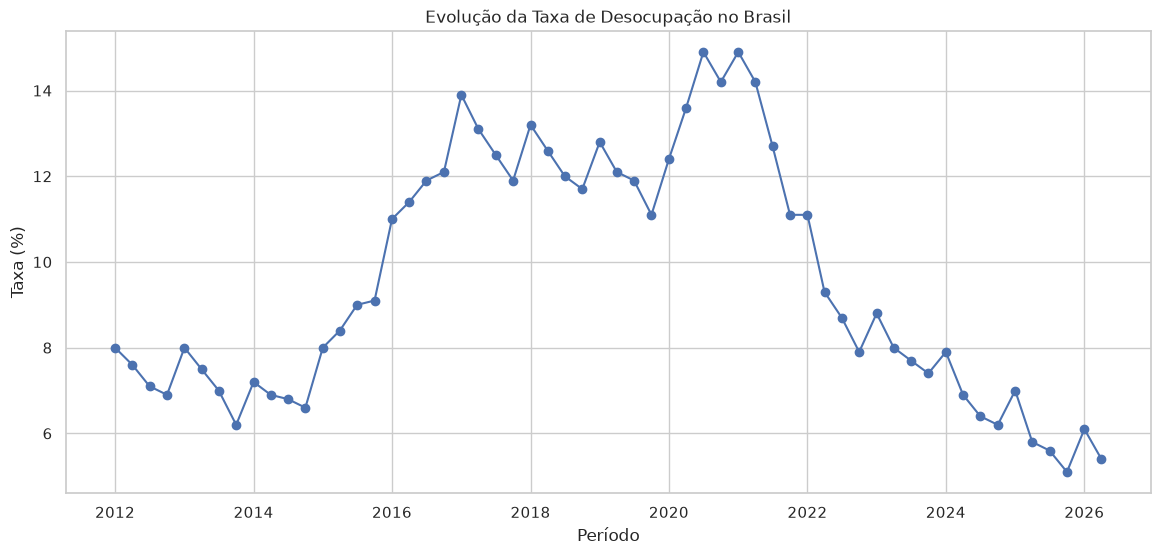

In [12]:
plt.figure(figsize=(14,6))
plt.plot(df['data'], df['taxa_desocupacao'], marker='o')
plt.title('Evolução da Taxa de Desocupação no Brasil')
plt.xlabel('Período')
plt.ylabel('Taxa (%)')
plt.show()

## RQ2 e RQ3 - Comparação anual

,ano,taxa_desocupacao
0,2012,7.400
1,2013,7.175
2,2014,6.875
3,2015,8.625
4,2016,11.600
5,2017,12.850
6,2018,12.375
7,2019,11.975
8,2020,13.775
9,2021,13.225


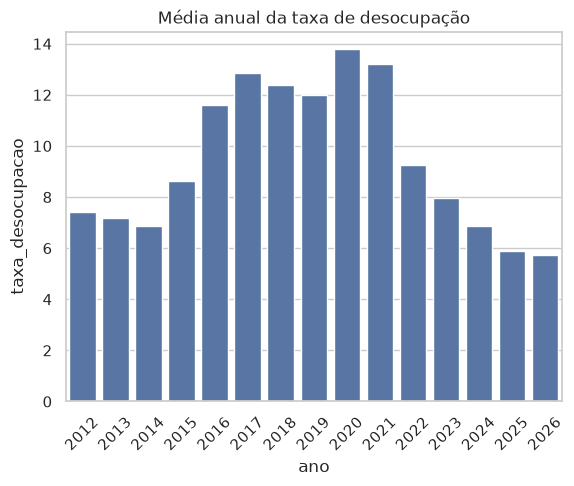

In [13]:
media_anual = df.groupby('ano')['taxa_desocupacao'].mean().reset_index()
display(media_anual)
sns.barplot(data=media_anual, x='ano', y='taxa_desocupacao')
plt.title('Média anual da taxa de desocupação')
plt.xticks(rotation=45)
plt.show()

## Distribuição das taxas

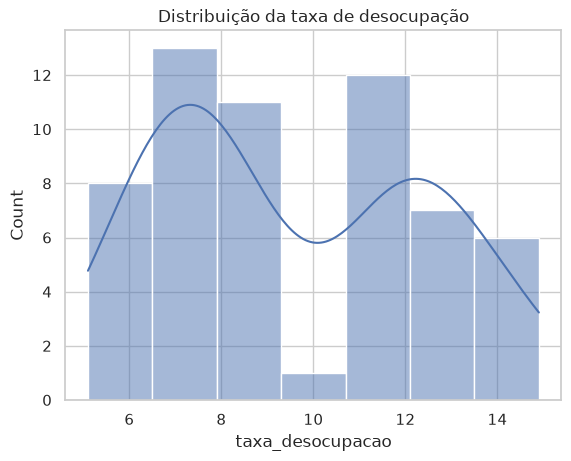

In [14]:
sns.histplot(data=df, x='taxa_desocupacao', kde=True)
plt.title('Distribuição da taxa de desocupação')
plt.show()

In [15]:

# Identificar a maior e a menor taxa de desocupação

maior_taxa = df.loc[df['taxa_desocupacao'].idxmax()]
menor_taxa = df.loc[df['taxa_desocupacao'].idxmin()]

print("MAIOR TAXA DE DESOCUPAÇÃO:")
print("Período:", maior_taxa['data'])
print("Taxa:", maior_taxa['taxa_desocupacao'], "%")

print("\nMENOR TAXA DE DESOCUPAÇÃO:")
print("Período:", menor_taxa['data'])
print("Taxa:", menor_taxa['taxa_desocupacao'], "%")



MAIOR TAXA DE DESOCUPAÇÃO:
Período: 2020-07-01 00:00:00
Taxa: 14.9 %

MENOR TAXA DE DESOCUPAÇÃO:
Período: 2025-10-01 00:00:00
Taxa: 5.1 %


In [16]:

# Ordenar as médias anuais

media_anual = df.groupby('ano')['taxa_desocupacao'].mean()

variacao_anual = media_anual.diff()

resultado_anual = pd.DataFrame({
    'Media (%)': media_anual,
    'Variacao em pontos percentuais': variacao_anual
})

display(resultado_anual.round(2))


,Media (%),Variacao em pontos percentuais
ano,,
2012,7.40,NaN
2013,7.18,-0.23
2014,6.87,-0.30
2015,8.62,1.75
2016,11.60,2.97
2017,12.85,1.25
2018,12.38,-0.47
2019,11.98,-0.40
2020,13.78,1.80


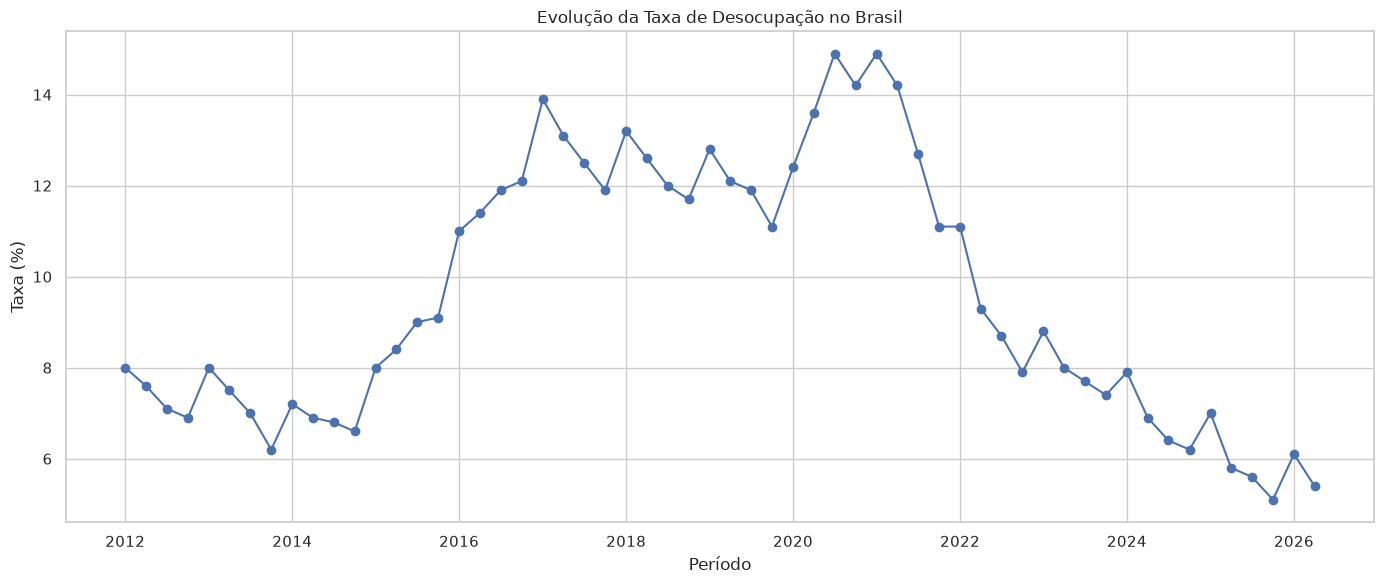

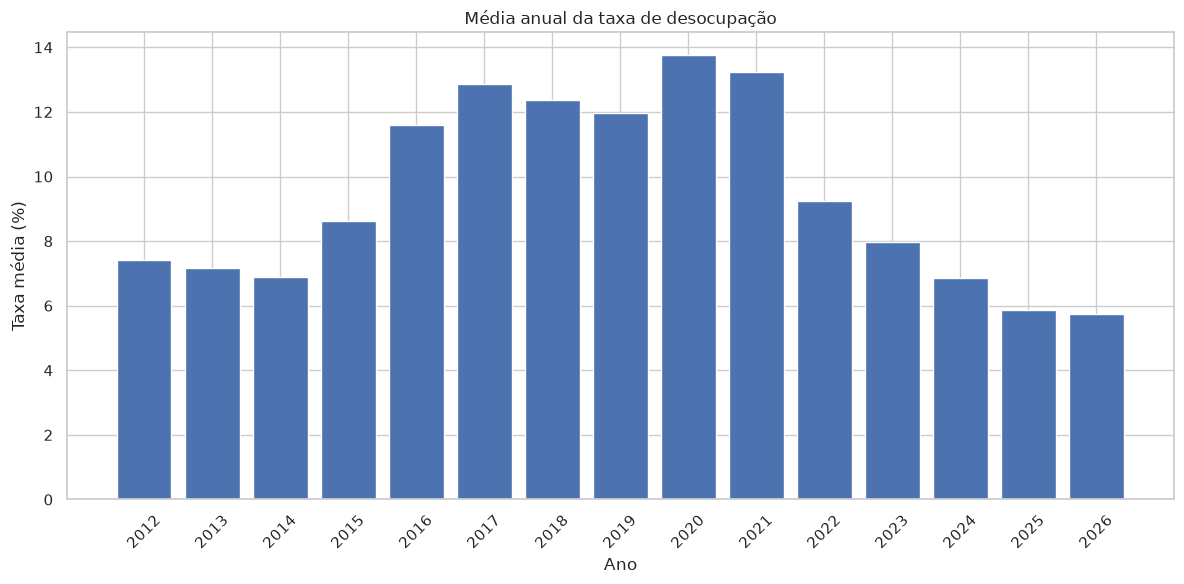

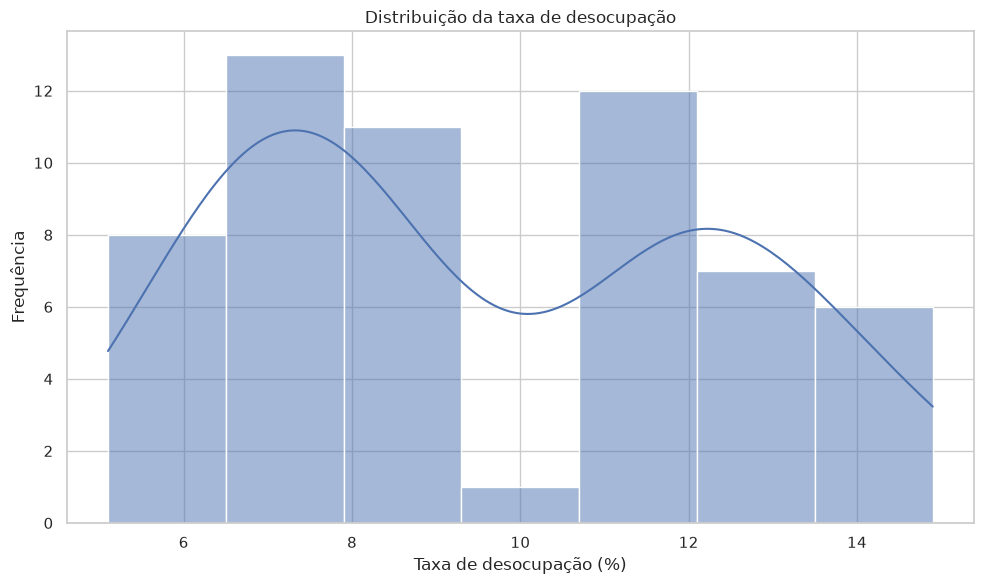

In [17]:

from pathlib import Path

# Criar a pasta para armazenar os gráficos
pasta_graficos = Path('../docs/assets')
pasta_graficos.mkdir(parents=True, exist_ok=True)

# Gráfico 1 - Evolução histórica
plt.figure(figsize=(14, 6))
plt.plot(df['data'], df['taxa_desocupacao'], marker='o')
plt.title('Evolução da Taxa de Desocupação no Brasil')
plt.xlabel('Período')
plt.ylabel('Taxa (%)')
plt.tight_layout()
plt.savefig(pasta_graficos / 'evolucao_historica.png', dpi=300)
plt.show()

# Gráfico 2 - Média anual
plt.figure(figsize=(12, 6))
plt.bar(media_anual.index.astype(str), media_anual.values)
plt.title('Média anual da taxa de desocupação')
plt.xlabel('Ano')
plt.ylabel('Taxa média (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(pasta_graficos / 'media_anual.png', dpi=300)
plt.show()

# Gráfico 3 - Distribuição das taxas
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='taxa_desocupacao', kde=True)
plt.title('Distribuição da taxa de desocupação')
plt.xlabel('Taxa de desocupação (%)')
plt.ylabel('Frequência')
plt.tight_layout()
plt.savefig(pasta_graficos / 'distribuicao_taxas.png', dpi=300)
plt.show()
